# Работа с данными изображения

**Цель работы:** изучить цветовые пространства, выделение контуров, шумоподавление, математическую морфологию и преобразования изображений.

В работе используются четыре изображения из каталога `images`. Все эксперименты воспроизводимы: генератор случайных чисел имеет фиксированное начальное значение. Для обработки применяется OpenCV, для визуализации — Matplotlib.

## 1. Подготовка данных

OpenCV читает цветные изображения в порядке каналов **BGR**, тогда как Matplotlib ожидает **RGB**. Поэтому сразу после чтения выполняется явное преобразование BGR → RGB. Для разумного времени вычислений большие снимки уменьшаются с сохранением пропорций.

In [2]:
from pathlib import Path
import math

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (14, 8),
    'axes.titlesize': 11,
    'figure.dpi': 110,
})

IMAGE_DIR = Path('images')
SUPPORTED = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
image_paths = sorted(p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in SUPPORTED)
assert image_paths, f'В каталоге {IMAGE_DIR.resolve()} не найдены изображения'

def read_rgb(path, max_side=900):
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise ValueError(f'Не удалось прочитать {path}')
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1.0:
        rgb = cv2.resize(rgb, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    return rgb

images = [read_rgb(path) for path in image_paths]
print(f'Найдено изображений: {len(images)}')
for path, image in zip(image_paths, images):
    print(f'{path.name}: {image.shape[1]}×{image.shape[0]} px')

Найдено изображений: 4
photo1.jpg: 600×582 px
photo2.jpg: 474×488 px
photo3.jpg: 900×675 px
photo4.jpg: 900×880 px


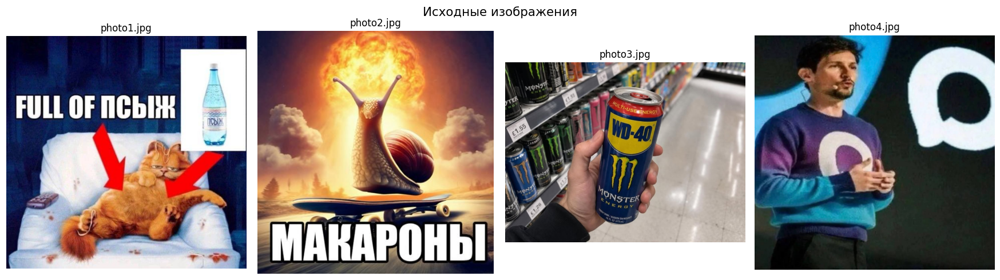

In [3]:
fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4.5))
axes = np.atleast_1d(axes)
for ax, path, image in zip(axes, image_paths, images):
    ax.imshow(image)
    ax.set_title(path.name)
    ax.axis('off')
plt.suptitle('Исходные изображения', fontsize=14)
plt.tight_layout()
plt.show()

## 2. Цветовые пространства: RGB → HSV → RGB

Выбрано пространство **HSV**:

- **H (Hue)** — цветовой тон;
- **S (Saturation)** — насыщенность;
- **V (Value)** — яркость.

В RGB цвет и яркость смешаны во всех трёх каналах. В HSV их можно обрабатывать раздельно. Это полезно для сегментации объектов по цвету, поиска дорожных знаков и разметки, коррекции освещения, трекинга цветных объектов, анализа растительности и подготовки масок.

В OpenCV для 8-битного изображения диапазон H равен 0…179, а S и V — 0…255. Обратное преобразование позволяет проверить потери, вызванные округлением.

In [4]:
def rgb_hsv_roundtrip(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    restored = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
    return hsv, restored

hsv_images, restored_images = [], []
rows = []
for path, image in zip(image_paths, images):
    hsv, restored = rgb_hsv_roundtrip(image)
    hsv_images.append(hsv)
    restored_images.append(restored)
    diff = np.abs(image.astype(np.int16) - restored.astype(np.int16))
    rows.append({
        'Файл': path.name,
        'MAE RGB→HSV→RGB': float(diff.mean()),
        'Макс. ошибка': int(diff.max()),
    })

pd.DataFrame(rows).round(4)

,Файл,MAE RGB→HSV→RGB,Макс. ошибка
0,photo1.jpg,0.3286,5
1,photo2.jpg,0.3636,4
2,photo3.jpg,0.3490,4
3,photo4.jpg,0.3495,5


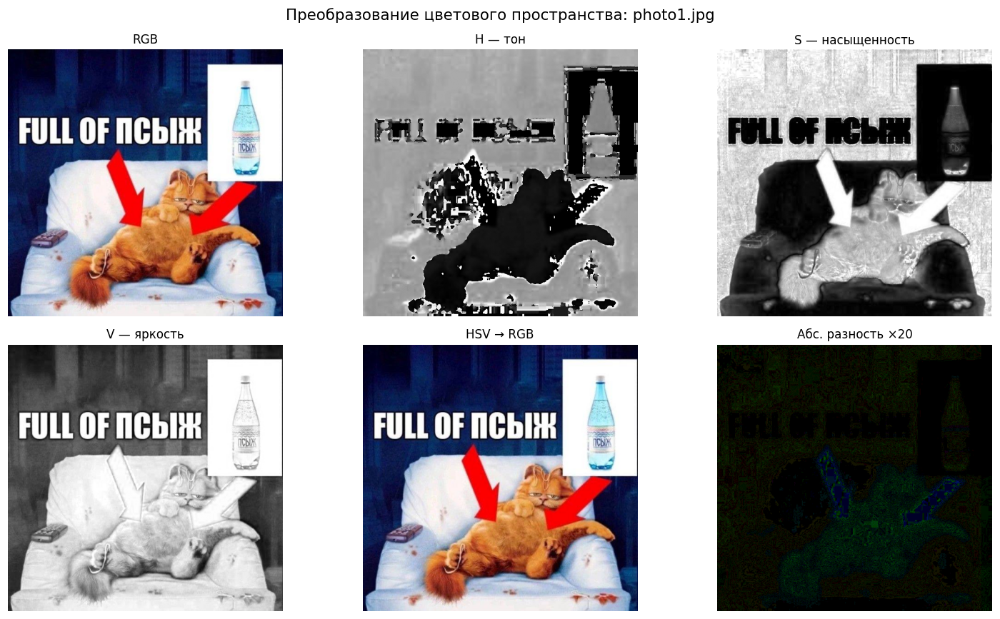

In [5]:
idx = 0
rgb, hsv, restored = images[idx], hsv_images[idx], restored_images[idx]
titles = ['RGB', 'H — тон', 'S — насыщенность', 'V — яркость', 'HSV → RGB', 'Абс. разность ×20']
views = [rgb, hsv[..., 0], hsv[..., 1], hsv[..., 2], restored,
         np.clip(np.abs(rgb.astype(np.int16) - restored.astype(np.int16)) * 20, 0, 255).astype(np.uint8)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, view, title in zip(axes.ravel(), views, titles):
    ax.imshow(view, cmap='gray' if view.ndim == 2 else None)
    ax.set_title(title)
    ax.axis('off')
plt.suptitle(f'Преобразование цветового пространства: {image_paths[idx].name}', fontsize=14)
plt.tight_layout()
plt.show()

**Наблюдение.** В канале H объекты различаются по цветовому тону почти независимо от яркости; канал S подчёркивает насыщенные области, а V соответствует освещённости. После HSV → RGB изображение визуально совпадает с исходным. Небольшая численная ошибка возможна из-за целочисленного округления.

## 3. Выделение контуров (Contours)

Последовательность обработки:

1. RGB → оттенки серого.
2. **CLAHE** (`clipLimit=2.0`) локально улучшает контраст при неравномерном освещении.
3. **Bilateral filter** (`d=7`, `sigmaColor=50`, `sigmaSpace=50`) подавляет шум, сохраняя границы.
4. Пороги **Canny** вычисляются от медианы яркости, поэтому алгоритм адаптируется к разным снимкам.
5. Морфологическое замыкание ядром 3×3 соединяет небольшие разрывы границ.
6. `findContours(..., RETR_EXTERNAL, CHAIN_APPROX_SIMPLE)` находит внешние контуры и сжимает прямолинейные участки. Слишком короткие и маленькие контуры отбрасываются.

In [6]:
def detect_contours(rgb, min_area_ratio=0.00025):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    smooth = cv2.bilateralFilter(clahe, d=7, sigmaColor=50, sigmaSpace=50)

    median = float(np.median(smooth))
    lower = int(max(0, 0.66 * median))
    upper = int(min(255, 1.33 * median))
    if upper <= lower:  # защита для почти однородного изображения
        lower, upper = 50, 150

    edges = cv2.Canny(smooth, lower, upper, L2gradient=True)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=1)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    min_area = rgb.shape[0] * rgb.shape[1] * min_area_ratio
    kept = [c for c in contours if cv2.contourArea(c) >= min_area and cv2.arcLength(c, True) >= 30]
    kept.sort(key=cv2.contourArea, reverse=True)

    visual = rgb.copy()
    cv2.drawContours(visual, kept, -1, (0, 255, 0), 2, lineType=cv2.LINE_AA)
    for i, contour in enumerate(kept[:10], start=1):
        x, y, w, h = cv2.boundingRect(contour)
        cv2.rectangle(visual, (x, y), (x + w, y + h), (255, 60, 30), 1)
        cv2.putText(visual, str(i), (x, max(12, y - 3)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.45, (255, 255, 0), 1, cv2.LINE_AA)
    return gray, smooth, edges, closed, kept, visual, (lower, upper)

contour_results = [detect_contours(image) for image in images]
pd.DataFrame([
    {'Файл': path.name, 'Порог Canny': str(result[6]), 'Контуров после фильтрации': len(result[4])}
    for path, result in zip(image_paths, contour_results)
])

,Файл,Порог Canny,Контуров после фильтрации
0,photo1.jpg,"(75, 151)",20
1,photo2.jpg,"(81, 163)",16
2,photo3.jpg,"(87, 176)",28
3,photo4.jpg,"(37, 75)",8


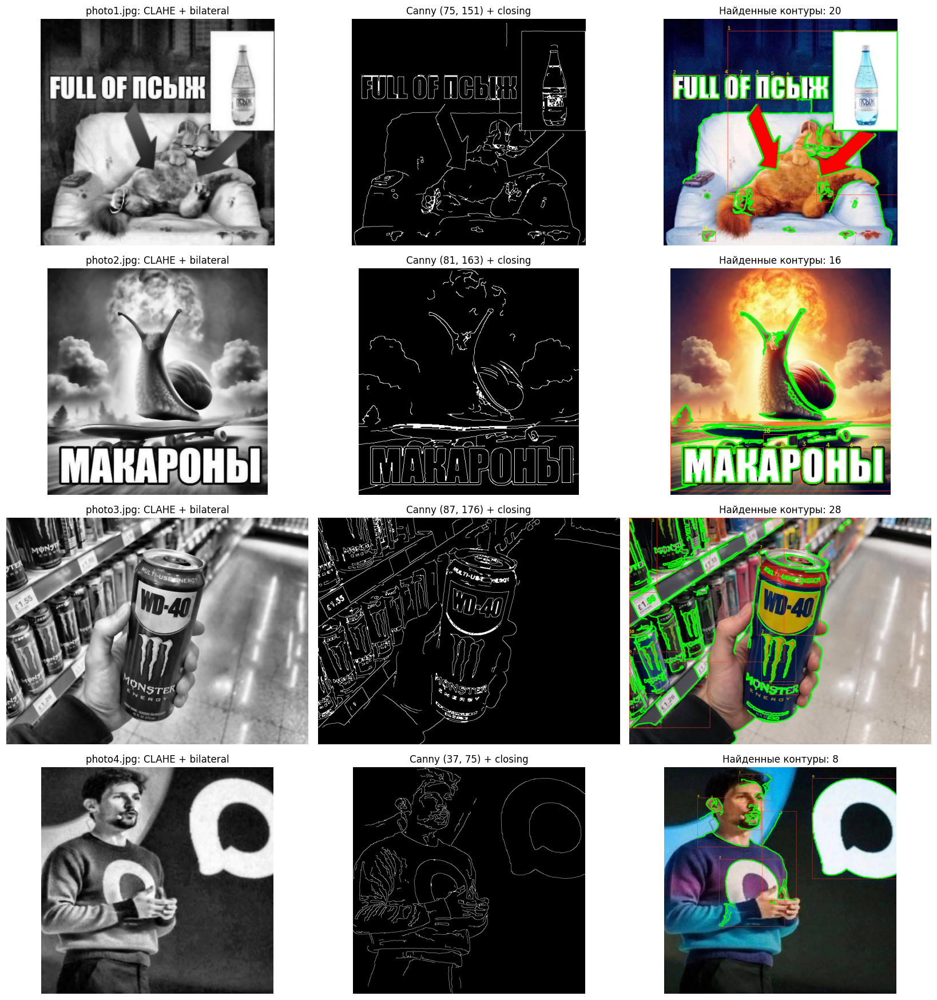

In [7]:
fig, axes = plt.subplots(len(images), 3, figsize=(15, 4 * len(images)))
if len(images) == 1:
    axes = axes[None, :]
for row, (path, result) in enumerate(zip(image_paths, contour_results)):
    gray, smooth, edges, closed, contours, visual, thresholds = result
    panels = [smooth, closed, visual]
    titles = [f'{path.name}: CLAHE + bilateral',
              f'Canny {thresholds} + closing',
              f'Найденные контуры: {len(contours)}']
    for ax, panel, title in zip(axes[row], panels, titles):
        ax.imshow(panel, cmap='gray' if panel.ndim == 2 else None)
        ax.set_title(title)
        ax.axis('off')
plt.tight_layout()
plt.show()

**Анализ.** Сглаживание уменьшает число ложных границ от мелкой текстуры и JPEG-артефактов. CLAHE делает слабые перепады яркости заметнее, а замыкание соединяет разорванные участки Canny. Фильтр площади оставляет визуально значимые объекты. При необходимости чувствительность регулируется `min_area_ratio`, коэффициентами порогов Canny и размером морфологического ядра.

## 4. Денойзинг (Denoising)

Чтобы сравнение было объективным, к исходному изображению добавляется воспроизводимый смешанный шум:

- гауссов шум с σ = 25;
- импульсный шум «соль и перец» для 1% пикселей.

Сравниваются четыре метода: Gaussian blur, median blur, bilateral filter и Non-Local Means (NLM). Качество оценивается относительно известного чистого оригинала:

- **MAE** — средняя абсолютная ошибка, меньше — лучше;
- **PSNR** — пиковое отношение сигнал/шум, больше — лучше.

PSNR — удобная численная метрика, но визуальную сохранность границ также нужно оценивать по изображениям.

In [8]:
rng = np.random.default_rng(42)

def add_mixed_noise(rgb, sigma=25, sp_ratio=0.01):
    noisy = rgb.astype(np.float32) + rng.normal(0, sigma, rgb.shape)
    noisy = np.clip(noisy, 0, 255).astype(np.uint8)
    mask = rng.random(rgb.shape[:2])
    noisy[mask < sp_ratio / 2] = 0
    noisy[(mask >= sp_ratio / 2) & (mask < sp_ratio)] = 255
    return noisy

def denoise_variants(noisy):
    return {
        'Gaussian 5×5': cv2.GaussianBlur(noisy, (5, 5), 0),
        'Median 5×5': cv2.medianBlur(noisy, 5),
        'Bilateral': cv2.bilateralFilter(noisy, 9, 75, 75),
        'NLM': cv2.fastNlMeansDenoisingColored(noisy, None, 8, 8, 7, 21),
    }

def mae(reference, test):
    return float(np.mean(np.abs(reference.astype(np.float32) - test.astype(np.float32))))

def psnr(reference, test):
    mse = np.mean((reference.astype(np.float32) - test.astype(np.float32)) ** 2)
    return float('inf') if mse == 0 else float(20 * np.log10(255.0 / np.sqrt(mse)))

noisy_images = [add_mixed_noise(image) for image in images]
all_denoised = [denoise_variants(noisy) for noisy in noisy_images]

metric_rows = []
for path, original, noisy, variants in zip(image_paths, images, noisy_images, all_denoised):
    for method, result in {'С шумом': noisy, **variants}.items():
        metric_rows.append({
            'Файл': path.name,
            'Метод': method,
            'MAE ↓': mae(original, result),
            'PSNR, dB ↑': psnr(original, result),
        })

metrics = pd.DataFrame(metric_rows)
metrics.round(2)

,Файл,Метод,MAE ↓,"PSNR, dB ↑"
0,photo1.jpg,С шумом,17.70,19.57
1,photo1.jpg,Gaussian 5×5,8.62,26.67
2,photo1.jpg,Median 5×5,6.56,28.52
3,photo1.jpg,Bilateral,7.94,23.27
4,photo1.jpg,NLM,13.75,20.87
5,photo2.jpg,С шумом,18.79,19.34
6,photo2.jpg,Gaussian 5×5,9.38,25.32
7,photo2.jpg,Median 5×5,7.27,26.73
8,photo2.jpg,Bilateral,8.17,23.42
9,photo2.jpg,NLM,14.11,20.94


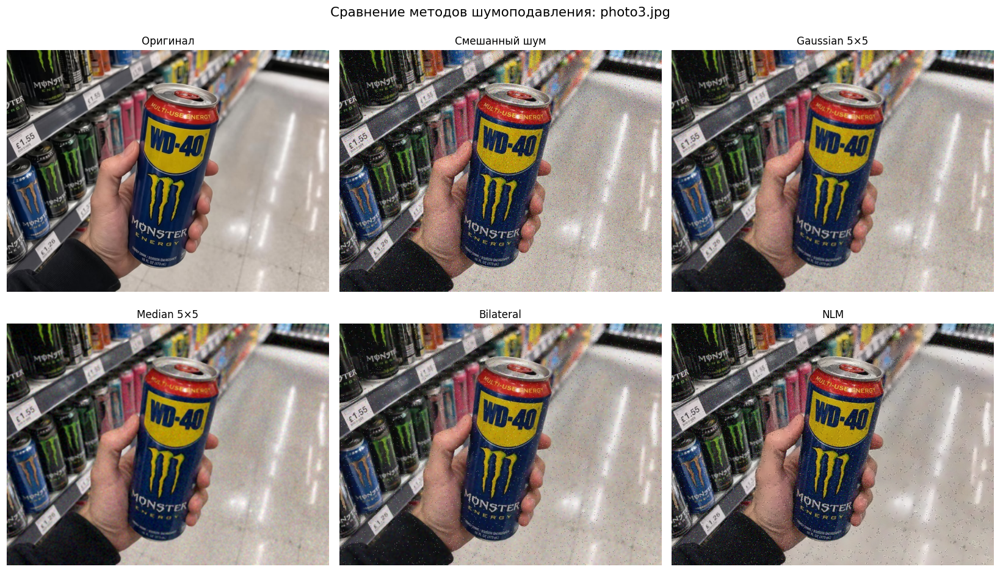

,MAE ↓,"PSNR, dB ↑"
Метод,,
Median 5×5,6.49,28.73
Gaussian 5×5,7.93,27.40
Bilateral,7.56,23.51
NLM,14.22,20.83


In [9]:
sample = min(2, len(images) - 1)
panels = [('Оригинал', images[sample]), ('Смешанный шум', noisy_images[sample])]
panels += list(all_denoised[sample].items())

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (title, panel) in zip(axes.ravel(), panels):
    ax.imshow(panel)
    ax.set_title(title)
    ax.axis('off')
plt.suptitle(f'Сравнение методов шумоподавления: {image_paths[sample].name}', fontsize=14)
plt.tight_layout()
plt.show()

summary = (metrics[metrics['Метод'] != 'С шумом']
           .groupby('Метод')[['MAE ↓', 'PSNR, dB ↑']]
           .mean()
           .sort_values('PSNR, dB ↑', ascending=False))
summary.round(2)

In [15]:
best_method = summary.index[0]
print(f'По среднему PSNR лучший метод на данном наборе: {best_method}.')

По среднему PSNR лучший метод на данном наборе: Median 5×5.


## 5. Математическая морфология

Морфологические операции применяются к бинарной маске:

- **эрозия** уменьшает белые области и удаляет мелкие белые точки;
- **дилатация** расширяет объекты и соединяет близкие области;
- **открытие** (эрозия → дилатация) удаляет небольшие светлые помехи;
- **замыкание** (дилатация → эрозия) закрывает отверстия и разрывы;
- **морфологический градиент** показывает границу объекта.

Маска получается методом Оцу: порог автоматически выбирается по гистограмме. Если белого фона слишком много, маска инвертируется, чтобы объектами считалась меньшая доля изображения.

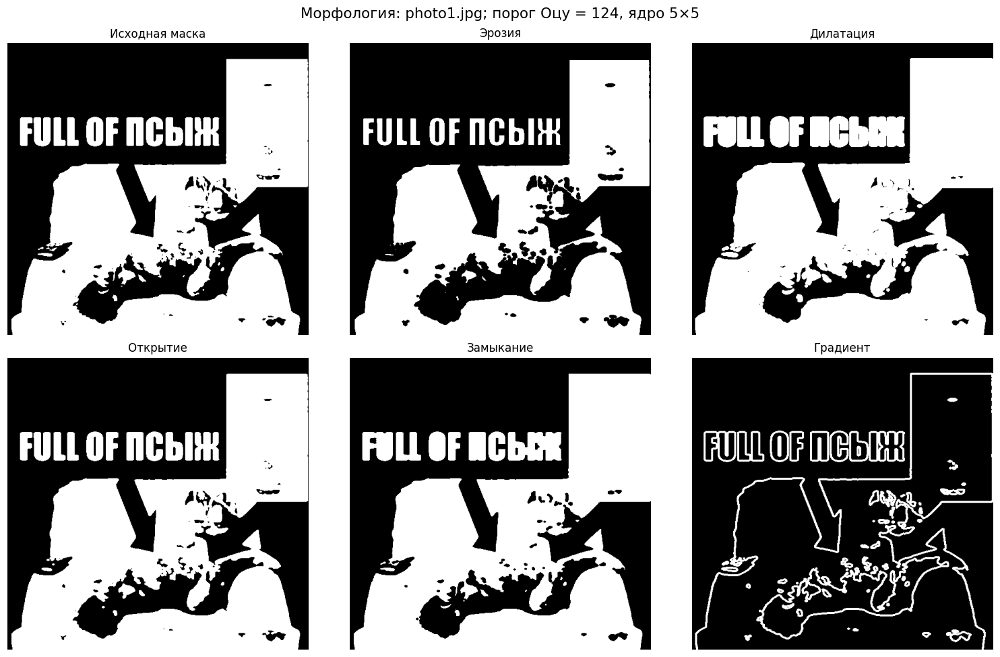

In [11]:
def make_binary_mask(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    threshold, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if np.count_nonzero(mask) > mask.size * 0.65:
        mask = cv2.bitwise_not(mask)
    return threshold, mask

def morphology(mask, kernel_size=5):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    return {
        'Исходная маска': mask,
        'Эрозия': cv2.erode(mask, kernel, iterations=1),
        'Дилатация': cv2.dilate(mask, kernel, iterations=1),
        'Открытие': cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel),
        'Замыкание': cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel),
        'Градиент': cv2.morphologyEx(mask, cv2.MORPH_GRADIENT, kernel),
    }

morph_results = []
for image in images:
    threshold, mask = make_binary_mask(image)
    morph_results.append((threshold, morphology(mask)))

idx = 0
threshold, operations = morph_results[idx]
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (title, result) in zip(axes.ravel(), operations.items()):
    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.suptitle(f'Морфология: {image_paths[idx].name}; порог Оцу = {threshold:.0f}, ядро 5×5', fontsize=14)
plt.tight_layout()
plt.show()

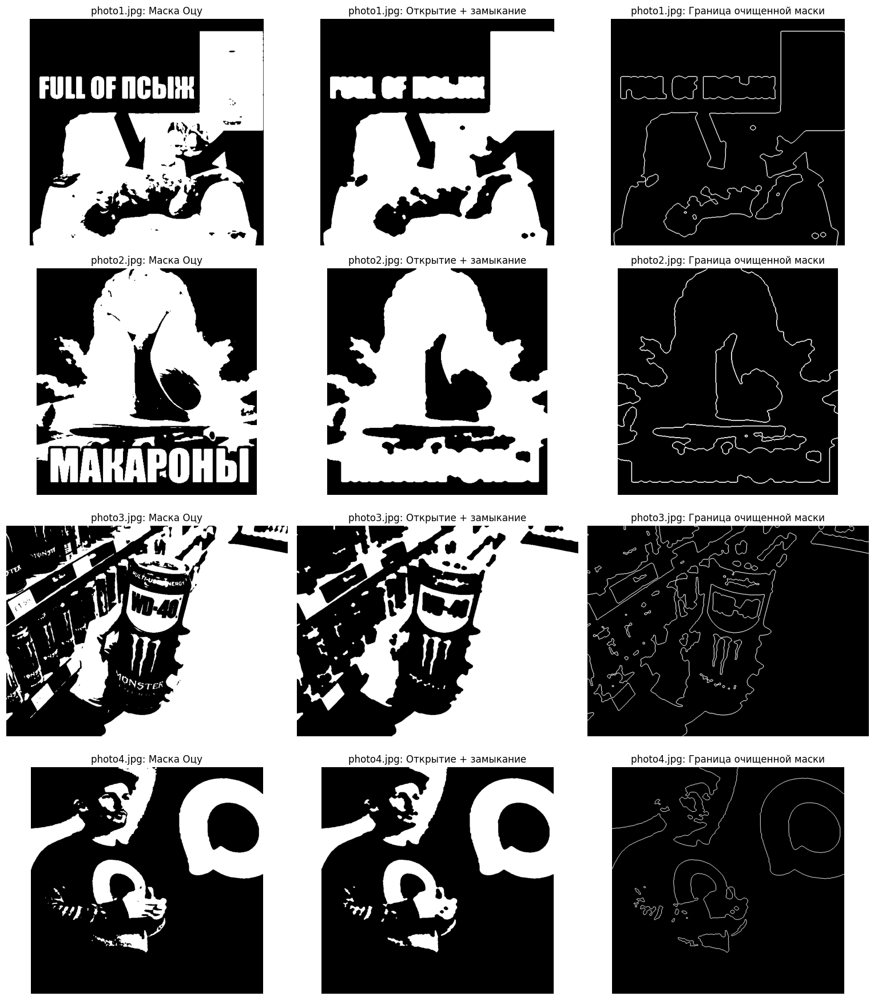

,Файл,Компонент до,Компонент после
0,photo1.jpg,26,7
1,photo2.jpg,28,2
2,photo3.jpg,172,39
3,photo4.jpg,61,22


In [12]:
# Практический пример: сравнение количества компонент до и после открытия + замыкания
component_rows = []
fig, axes = plt.subplots(len(images), 3, figsize=(14, 4 * len(images)))
if len(images) == 1:
    axes = axes[None, :]

for row, (path, image, (threshold, operations)) in enumerate(zip(image_paths, images, morph_results)):
    raw = operations['Исходная маска']
    cleaned = cv2.morphologyEx(operations['Открытие'], cv2.MORPH_CLOSE,
                               cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)), iterations=2)
    gradient = cv2.morphologyEx(cleaned, cv2.MORPH_GRADIENT,
                                cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
    n_raw = cv2.connectedComponents(raw)[0] - 1
    n_clean = cv2.connectedComponents(cleaned)[0] - 1
    component_rows.append({'Файл': path.name, 'Компонент до': n_raw, 'Компонент после': n_clean})
    for ax, panel, title in zip(axes[row], [raw, cleaned, gradient],
                                ['Маска Оцу', 'Открытие + замыкание', 'Граница очищенной маски']):
        ax.imshow(panel, cmap='gray')
        ax.set_title(f'{path.name}: {title}')
        ax.axis('off')

plt.tight_layout()
plt.show()
pd.DataFrame(component_rows)

**Анализ.** Открытие уменьшает количество мелких изолированных компонент, а замыкание объединяет близкие фрагменты и заполняет небольшие разрывы. За счёт этого маска становится стабильнее, а её морфологический градиент образует более цельные контуры. Слишком большое ядро может удалить тонкие детали или слить разные объекты, поэтому его размер выбирают относительно масштаба объектов.

## 6. Преобразования изображений (Image Transformation)

Выполним поворот, масштабирование и сдвиг с помощью аффинных преобразований. Затем изменим яркость и контраст и применим сглаживающий и повышающий резкость фильтры.

- Для уменьшения используется `INTER_AREA`, хорошо усредняющий пиксели.
- Поворот и сдвиг выполняются `warpAffine`; отражение границы уменьшает появление чёрных полей.
- Яркость/контраст задаются формулой `new = α·image + β`.
- Gaussian blur подавляет высокочастотный шум.
- Unsharp masking повышает локальный контраст границ.

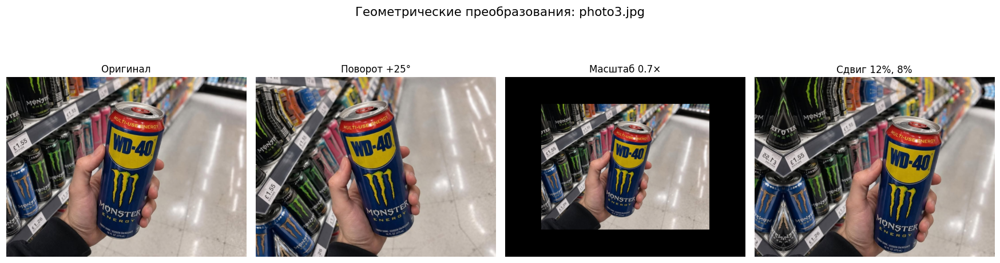

In [13]:
def rotate_image(rgb, angle=25):
    h, w = rgb.shape[:2]
    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(rgb, matrix, (w, h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REFLECT)

def scale_on_canvas(rgb, factor=0.7):
    h, w = rgb.shape[:2]
    scaled = cv2.resize(rgb, None, fx=factor, fy=factor,
                        interpolation=cv2.INTER_AREA if factor < 1 else cv2.INTER_CUBIC)
    canvas = np.zeros_like(rgb)
    sh, sw = scaled.shape[:2]
    y0, x0 = (h - sh) // 2, (w - sw) // 2
    canvas[y0:y0 + sh, x0:x0 + sw] = scaled
    return canvas

def translate_image(rgb, dx_ratio=0.12, dy_ratio=0.08):
    h, w = rgb.shape[:2]
    matrix = np.float32([[1, 0, w * dx_ratio], [0, 1, h * dy_ratio]])
    return cv2.warpAffine(rgb, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)

def photometric_and_filters(rgb):
    brighter = cv2.convertScaleAbs(rgb, alpha=1.0, beta=40)
    contrast = cv2.convertScaleAbs(rgb, alpha=1.35, beta=-25)
    blurred = cv2.GaussianBlur(rgb, (9, 9), 0)
    sharpened = cv2.addWeighted(rgb, 1.7, cv2.GaussianBlur(rgb, (0, 0), 2), -0.7, 0)
    return brighter, contrast, blurred, sharpened

idx = min(2, len(images) - 1)
image = images[idx]
geometric = [
    ('Оригинал', image),
    ('Поворот +25°', rotate_image(image, 25)),
    ('Масштаб 0.7×', scale_on_canvas(image, 0.7)),
    ('Сдвиг 12%, 8%', translate_image(image)),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, (title, result) in zip(axes, geometric):
    ax.imshow(result)
    ax.set_title(title)
    ax.axis('off')
plt.suptitle(f'Геометрические преобразования: {image_paths[idx].name}', fontsize=14)
plt.tight_layout()
plt.show()

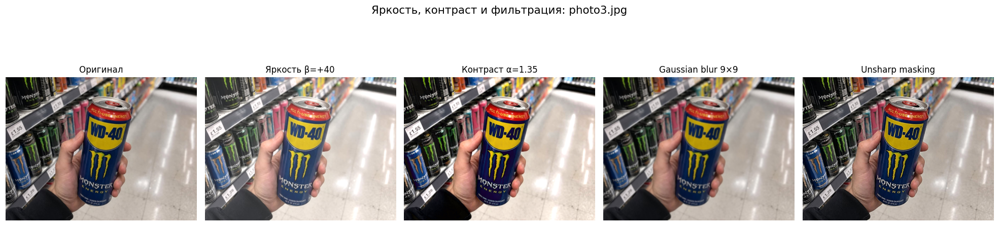

In [14]:
brighter, contrast, blurred, sharpened = photometric_and_filters(image)
panels = [
    ('Оригинал', image),
    ('Яркость β=+40', brighter),
    ('Контраст α=1.35', contrast),
    ('Gaussian blur 9×9', blurred),
    ('Unsharp masking', sharpened),
]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for ax, (title, result) in zip(axes, panels):
    ax.imshow(result)
    ax.set_title(title)
    ax.axis('off')
plt.suptitle(f'Яркость, контраст и фильтрация: {image_paths[idx].name}', fontsize=14)
plt.tight_layout()
plt.show()

### Роль преобразований в предобработке

Геометрические преобразования применяются для нормализации положения и размера объекта, совмещения кадров и аугментации обучающих данных. Изменение яркости и контраста помогает компенсировать различия освещения и сделать важные детали заметнее. Сглаживание снижает шум перед сегментацией и Canny, а повышение резкости подчёркивает границы перед распознаванием. Параметры следует выбирать умеренно: чрезмерное размытие удаляет мелкие детали, а чрезмерная резкость усиливает шум.

## 7. Итоговые выводы

1. HSV разделяет цветовой тон, насыщенность и яркость, поэтому удобен для цветовой сегментации и коррекции освещения. Обратное преобразование практически восстанавливает RGB.
2. Надёжность контуров улучшили локальное выравнивание контраста, bilateral-фильтр, адаптивные пороги Canny, морфологическое замыкание и фильтрация по площади.
3. Для смешанного шума методы дают разный компромисс между подавлением шума и сохранением деталей. Лучший метод для этих изображений определяется выше по среднему PSNR, а визуальная оценка показывает сохранность границ.
4. Эрозия, дилатация, открытие и замыкание позволяют удалять мелкие дефекты, соединять разрывы и получать более цельные маски и контуры.
5. Геометрические и фотометрические преобразования нормализуют входные данные, а фильтрация готовит изображения к последующей сегментации, выделению признаков и распознаванию.